# Activity No. 1


**Project Title:** Steel Mechanical Property Prediction and Classification

**Course:** Artificial Intelligence and Machine Learning  
**Class:** TY B.Tech Computer Engineering  
**Semester:** V  
**Academic Year:** 2026–2027  

## Group Details
### Group Members and Individual Contributions

**Group Member 1: Akhilesh Kombe**  
**PRN:** 202401040244  
**Contribution:** Dataset preprocessing, regression model implementation and evaluation.

**Group Member 2: Sanket Kakde**  
**PRN:** 202401040245  
**Contribution:** Classification model implementation, performance evaluation and visualization.

**Group Member 3: Devansh Agrawal**  
**PRN:** 202401040270  
**Contribution:** Cross-validation, model optimization, comparative analysis and documentation.

### Team Collaboration

All three group members participated in reviewing the experimental results, comparing machine learning algorithms, interpreting model performance and preparing the project presentation.


## Project Title
Comparative Analysis of Machine Learning Algorithms for Steel Mechanical Property Prediction and Classification

## Aim
To implement, evaluate, and compare different machine learning algorithms for predicting tensile strength and classifying steel materials based on their chemical composition and physical properties.

## Objectives
1. Understand and explore real-world steel material datasets.
2. Perform data preprocessing and visualization.
3. Implement multiple regression and classification algorithms.
4. Evaluate performance using suitable metrics.
5. Compare algorithms and optimize their performance.
6. Identify suitable machine learning models and draw conclusions.


In [13]:

!pip -q install numpy pandas matplotlib seaborn scikit-learn
print("Required libraries installed successfully!")


Required libraries installed successfully!


In [14]:

from google.colab import files
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

uploaded = files.upload()

steel = pd.read_csv("steel_db_cleaned.csv")
matnavi = pd.read_csv("matnavi_cleaned.csv")

print("DATASETS LOADED SUCCESSFULLY!")
print("Steel dataset:", steel.shape)
print("MatNavi dataset:", matnavi.shape)

print("\nSteel Dataset Preview:")
display(steel.head())

print("\nMatNavi Dataset Preview:")
display(matnavi.head())


Saving matnavi_cleaned.csv to matnavi_cleaned (3).csv
Saving steel_db_cleaned.csv to steel_db_cleaned (3).csv
DATASETS LOADED SUCCESSFULLY!
Steel dataset: (3234, 25)
MatNavi dataset: (915, 21)

Steel Dataset Preview:


,name,processing_condition,al,cu,mn,n,ni,ti,s,fe,...,co,c,nb,b,cr,tensile_strength_mpa,yield_strength_mpa,ductility_pct,cluster_number,cluster_label
0,AISI 4023 Steel,"Normalized At 925C (1700F), Machined To 25 mm ...",0.0,0.0,0.8,0.0,0.0,0.0,0.04,98.40,...,0.0,0.225,0.0,0.0,0.0,745,440,21,0,Carburized – quenched (oil) – wear-resistant s...
1,AISI 4027 Steel,"Water Quenched 865C (1590F), 540C (1000F) Temp...",0.0,0.0,0.8,0.0,0.0,0.0,0.04,98.35,...,0.0,0.275,0.0,0.0,0.0,689,510,25,10,Quenched (water) & tempered – high-strength st...
2,AISI 4027 Steel,"Water Quenched 865C (1590F), 480C (900F) Tempe...",0.0,0.0,0.8,0.0,0.0,0.0,0.04,98.35,...,0.0,0.275,0.0,0.0,0.0,786,615,22,10,Quenched (water) & tempered – high-strength st...
3,AISI 4027 Steel,"Water Quenched 865C (1590F), 480C (900F) Tempe...",0.0,0.0,0.8,0.0,0.0,0.0,0.04,98.35,...,0.0,0.275,0.0,0.0,0.0,1035,917,16,10,Quenched (water) & tempered – high-strength st...
4,AISI 4027 Steel,"Water Quenched 865C (1590F), 595C (1100F) Temp...",0.0,0.0,0.8,0.0,0.0,0.0,0.04,98.35,...,0.0,0.275,0.0,0.0,0.0,717,550,24,10,Quenched (water) & tempered – high-strength st...



MatNavi Dataset Preview:


,alloy_code,c,si,mn,p,s,ni,cr,mo,cu,...,al,n,ceq,nb_ta,temperature_c,proof_stress_mpa,tensile_strength_mpa,elongation_pct,reduction_in_area_pct,is_outlier
0,MBB,0.12,0.36,0.52,0.009,0.003,0.089,0.97,0.61,0.04,...,0.003,0.0066,0.0,0.0,27,342,490,30,71,False
1,MBB,0.12,0.36,0.52,0.009,0.003,0.089,0.97,0.61,0.04,...,0.003,0.0066,0.0,0.0,100,338,454,27,72,False
2,MBB,0.12,0.36,0.52,0.009,0.003,0.089,0.97,0.61,0.04,...,0.003,0.0066,0.0,0.0,200,337,465,23,69,False
3,MBB,0.12,0.36,0.52,0.009,0.003,0.089,0.97,0.61,0.04,...,0.003,0.0066,0.0,0.0,300,346,495,21,70,False
4,MBB,0.12,0.36,0.52,0.009,0.003,0.089,0.97,0.61,0.04,...,0.003,0.0066,0.0,0.0,400,316,489,26,79,False



## Phase 1: Data Exploration and Statistical Analysis

The project uses two material datasets:

- Steel Database: 3,234 records containing chemical composition, tensile strength, yield strength, and material information.
- MatNavi Dataset: 915 records containing chemical composition, testing temperature, tensile strength, proof stress, and ductility-related properties.

The aim of data exploration is to understand variable distributions, missing values, and relationships between features and the prediction target.


STEEL DATASET INFORMATION
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3234 entries, 0 to 3233
Data columns (total 25 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   name                  3234 non-null   object 
 1   processing_condition  3234 non-null   object 
 2   al                    3234 non-null   float64
 3   cu                    3234 non-null   float64
 4   mn                    3234 non-null   float64
 5   n                     3234 non-null   float64
 6   ni                    3234 non-null   float64
 7   ti                    3234 non-null   float64
 8   s                     3234 non-null   float64
 9   fe                    3234 non-null   float64
 10  zr                    3234 non-null   float64
 11  p                     3234 non-null   float64
 12  si                    3234 non-null   float64
 13  v                     3234 non-null   float64
 14  mo                    3234 non-null   float64


,al,cu,mn,n,ni,ti,s,fe,zr,p,...,mo,co,c,nb,b,cr,tensile_strength_mpa,yield_strength_mpa,ductility_pct,cluster_number
count,3234.000000,3234.000000,3234.000000,3234.000000,3234.000000,3234.000000,3234.000000,3234.000000,3234.000000,3234.000000,...,3234.000000,3234.000000,3234.000000,3234.000000,3234.000000,3234.000000,3234.000000,3234.000000,3234.000000,3234.000000
mean,0.002665,0.024558,0.794136,0.000155,1.001419,0.007978,0.045020,96.470635,0.000489,0.035015,...,0.222587,0.122140,0.313736,0.000912,0.000128,0.711395,858.663575,648.439085,18.905071,4.573593
std,0.038439,0.161402,0.295663,0.003389,2.621791,0.079494,0.032875,5.087984,0.005601,0.011770,...,0.539361,1.035296,0.167891,0.008954,0.000543,2.234127,314.029873,310.583216,5.759642,3.251257
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,50.220000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,275.000000,159.000000,3.000000,0.000000
25%,0.000000,0.000000,0.575000,0.000000,0.000000,0.000000,0.040000,96.855000,0.000000,0.035000,...,0.000000,0.000000,0.200000,0.000000,0.000000,0.000000,635.000000,415.000000,15.000000,1.000000
50%,0.000000,0.000000,0.800000,0.000000,0.000000,0.000000,0.040000,97.420000,0.000000,0.035000,...,0.200000,0.000000,0.270000,0.000000,0.000000,0.500000,828.000000,596.000000,18.000000,5.000000
75%,0.000000,0.000000,0.875000,0.000000,0.850000,0.000000,0.040000,98.055000,0.000000,0.040000,...,0.250000,0.000000,0.405000,0.000000,0.000000,0.800000,1025.000000,841.000000,22.000000,7.000000
max,1.200000,3.000000,2.000000,0.150000,20.500000,1.400000,0.400000,99.790000,0.100000,0.350000,...,4.800000,12.000000,1.100000,0.250000,0.010000,25.500000,2451.000000,2395.000000,46.000000,11.000000



MATNAVI STATISTICAL SUMMARY


,c,si,mn,p,s,ni,cr,mo,cu,v,al,n,ceq,nb_ta,temperature_c,proof_stress_mpa,tensile_strength_mpa,elongation_pct,reduction_in_area_pct
count,915.000000,915.000000,915.000000,915.000000,915.000000,915.000000,915.000000,915.000000,915.000000,915.000000,915.000000,915.000000,915.000000,915.000000,915.000000,915.000000,915.000000,915.000000,915.000000
mean,0.174929,0.310918,0.812962,0.014543,0.010602,0.143016,0.427861,0.442870,0.079148,0.060190,0.012435,0.007652,0.093989,0.000041,351.601093,328.218579,496.248087,26.789071,70.206557
std,0.059674,0.086871,0.342775,0.005244,0.004024,0.172746,0.457568,0.394383,0.058481,0.096403,0.013067,0.002321,0.172533,0.000261,189.714773,131.653232,239.710650,8.806595,12.389289
min,0.090000,0.180000,0.420000,0.006000,0.003000,0.000000,0.000000,0.005000,0.000000,0.000000,0.002000,0.002500,0.000000,0.000000,27.000000,27.000000,162.000000,10.000000,18.000000
25%,0.130000,0.240000,0.500000,0.010000,0.008000,0.023000,0.040000,0.050000,0.040000,0.000000,0.004000,0.006200,0.000000,0.000000,200.000000,220.000000,413.000000,20.000000,62.000000
50%,0.160000,0.300000,0.680000,0.014000,0.010000,0.050000,0.110000,0.500000,0.070000,0.000000,0.006000,0.007600,0.000000,0.000000,400.000000,290.000000,479.000000,26.000000,71.000000
75%,0.200000,0.370000,1.210000,0.018000,0.012000,0.210000,1.000000,0.560000,0.110000,0.070000,0.016000,0.009000,0.000000,0.000000,500.000000,432.500000,575.000000,31.000000,80.000000
max,0.340000,0.520000,1.480000,0.030000,0.022000,0.600000,1.310000,1.350000,0.250000,0.300000,0.050000,0.015000,0.437000,0.001700,650.000000,690.000000,6661.000000,78.000000,94.000000



MISSING VALUES - STEEL


,Missing Values
name,0
processing_condition,0
al,0
cu,0
mn,0
n,0
ni,0
ti,0
s,0
fe,0



MISSING VALUES - MATNAVI


,Missing Values
alloy_code,0
c,0
si,0
mn,0
p,0
s,0
ni,0
cr,0
mo,0
cu,0


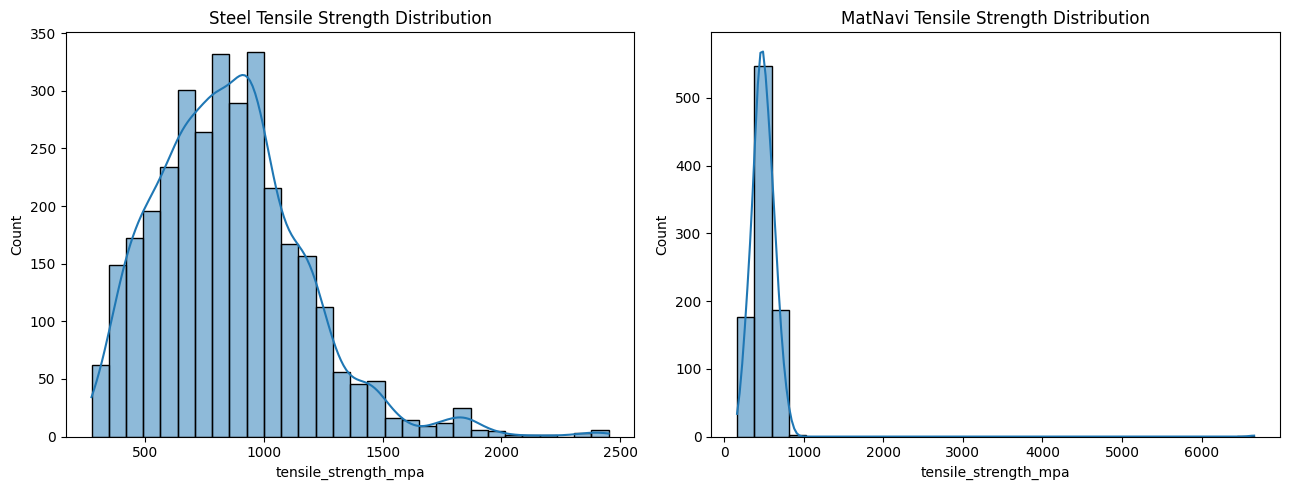

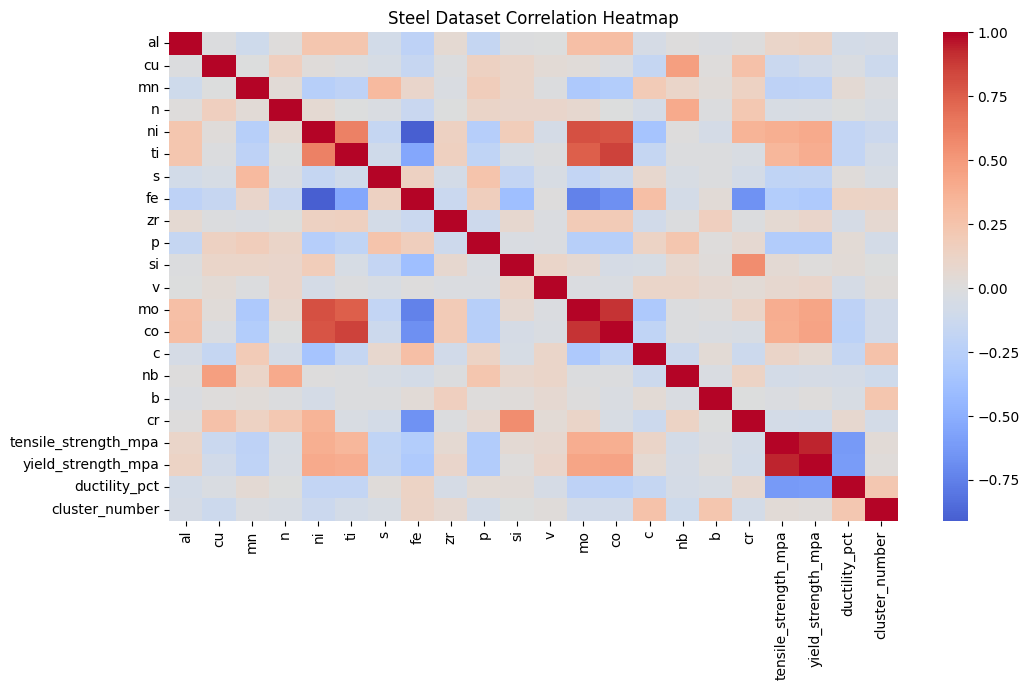

In [16]:

print("STEEL DATASET INFORMATION")
steel.info()

print("\nMATNAVI DATASET INFORMATION")
matnavi.info()

print("\nSTEEL STATISTICAL SUMMARY")
display(steel.describe())

print("\nMATNAVI STATISTICAL SUMMARY")
display(matnavi.describe())

print("\nMISSING VALUES - STEEL")
display(steel.isnull().sum().to_frame("Missing Values"))

print("\nMISSING VALUES - MATNAVI")
display(matnavi.isnull().sum().to_frame("Missing Values"))

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

sns.histplot(
    steel["tensile_strength_mpa"],
    bins=30, kde=True, ax=axes[0]
)
axes[0].set_title("Steel Tensile Strength Distribution")

sns.histplot(
    matnavi["tensile_strength_mpa"],
    bins=30, kde=True, ax=axes[1]
)
axes[1].set_title("MatNavi Tensile Strength Distribution")

plt.tight_layout()
plt.savefig("01_strength_distribution.png", dpi=200)
plt.show()

plt.figure(figsize=(11, 7))
sns.heatmap(
    steel.select_dtypes(include=np.number).corr(),
    cmap="coolwarm", center=0
)
plt.title("Steel Dataset Correlation Heatmap")
plt.tight_layout()
plt.savefig("02_correlation_heatmap.png", dpi=200)
plt.show()



## Phase 2: Regression Model Implementation

### Problem Statement
Predict the tensile strength of steel materials in MPa using their chemical composition and available testing information.

### Algorithms
1. Linear Regression
2. Ridge Regression
3. Decision Tree Regressor
4. K-Nearest Neighbors Regressor
5. Support Vector Regressor
6. Random Forest Regressor

### Methodology
- Select relevant input features.
- Split the data into 80% training and 20% testing.
- Handle missing values and scale numerical features.
- Train the algorithms using the training dataset.
- Evaluate predictions using MAE, MSE, RMSE and R² Score.

Steel and MatNavi will be evaluated separately because their material records and testing conditions differ.


In [17]:

from sklearn.model_selection import train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.tree import DecisionTreeRegressor
from sklearn.neighbors import KNeighborsRegressor
from sklearn.svm import SVR
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import (
    mean_absolute_error, mean_squared_error, r2_score
)

steel_features = [
    "al", "cu", "mn", "n", "ni", "ti",
    "s", "fe", "zr", "p", "si", "v",
    "mo", "co", "c", "nb", "b", "cr"
]

matnavi_features = [
    "c", "si", "mn", "p", "s", "ni",
    "cr", "mo", "cu", "v", "al",
    "n", "ceq", "nb_ta", "temperature_c"
]

datasets = {
    "Steel": (steel, steel_features),
    "MatNavi": (matnavi, matnavi_features)
}

regression_models = {
    "Linear Regression": LinearRegression(),
    "Ridge": Ridge(alpha=10),
    "Decision Tree": DecisionTreeRegressor(
        max_depth=8, random_state=42
    ),
    "KNN": KNeighborsRegressor(n_neighbors=5),
    "SVR": SVR(kernel="rbf"),
    "Random Forest": RandomForestRegressor(
        n_estimators=100, random_state=42, n_jobs=-1
    )
}

regression_results = []
regression_predictions = {}

for dataset_name, (df, features) in datasets.items():

    X = df[features]
    y = df["tensile_strength_mpa"]

    X_train_r, X_test_r, y_train_r, y_test_r = (
        train_test_split(
            X, y, test_size=0.2, random_state=42
        )
    )

    for model_name, model in regression_models.items():

        pipeline = make_pipeline(
            SimpleImputer(strategy="median"),
            StandardScaler(),
            model
        )

        pipeline.fit(X_train_r, y_train_r)
        pred = pipeline.predict(X_test_r)

        mae = mean_absolute_error(y_test_r, pred)
        mse = mean_squared_error(y_test_r, pred)
        rmse = np.sqrt(mse)
        r2 = r2_score(y_test_r, pred)

        regression_results.append({
            "Dataset": dataset_name,
            "Algorithm": model_name,
            "MAE": round(mae, 3),
            "MSE": round(mse, 3),
            "RMSE": round(rmse, 3),
            "R2": round(r2, 4)
        })

        regression_predictions[(dataset_name, model_name)] = (
            y_test_r.to_numpy(), pred
        )

regression_df = pd.DataFrame(regression_results)

print("REGRESSION PERFORMANCE COMPARISON")
display(regression_df)

regression_df.to_csv(
    "regression_results.csv", index=False
)


REGRESSION PERFORMANCE COMPARISON


,Dataset,Algorithm,MAE,MSE,RMSE,R2
0,Steel,Linear Regression,199.212,67188.760,259.208,0.2826
1,Steel,Ridge,199.343,66943.685,258.735,0.2853
2,Steel,Decision Tree,127.034,32025.333,178.956,0.6581
3,Steel,KNN,141.207,41330.350,203.299,0.5587
4,Steel,SVR,222.748,85093.810,291.708,0.0915
5,Steel,Random Forest,123.251,31072.501,176.274,0.6682
6,MatNavi,Linear Regression,68.645,6778.815,82.334,0.5187
7,MatNavi,Ridge,67.693,6532.560,80.824,0.5362
8,MatNavi,Decision Tree,26.226,1724.079,41.522,0.8776
9,MatNavi,KNN,50.714,11179.257,105.732,0.2063


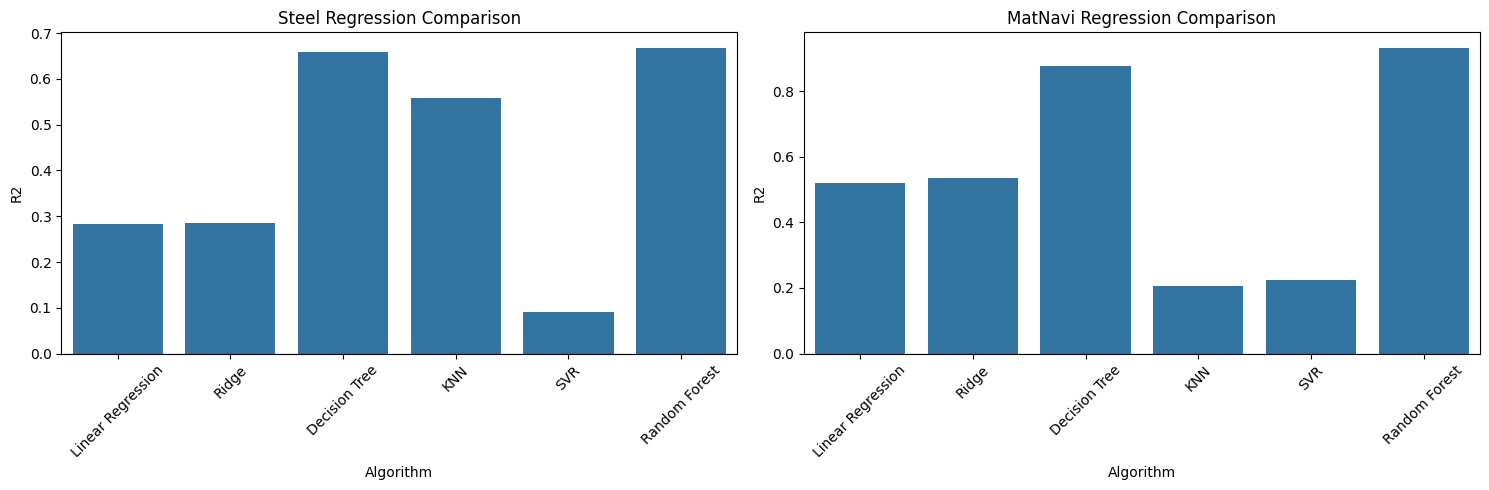

BEST REGRESSION MODEL FOR EACH DATASET

Dataset: Steel
Best Algorithm: Random Forest
MAE: 123.251
RMSE: 176.274
R2 Score: 0.6682


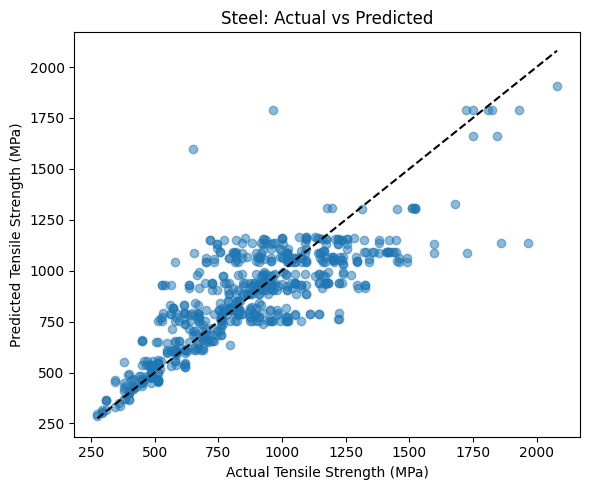


Dataset: MatNavi
Best Algorithm: Random Forest
MAE: 19.789
RMSE: 30.83
R2 Score: 0.9325


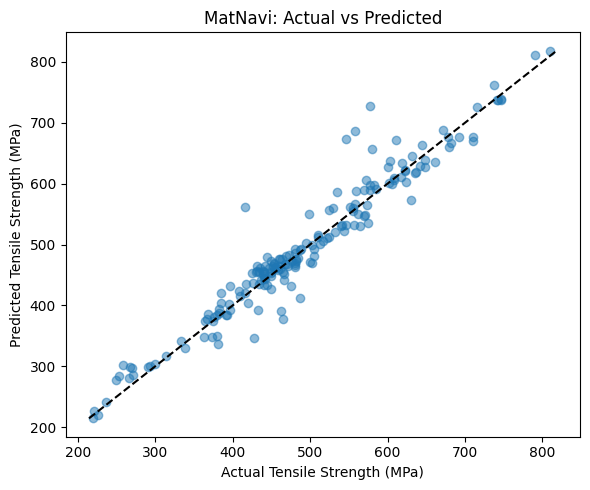

In [18]:

fig, axes = plt.subplots(1, 2, figsize=(15, 5))

for ax, dataset_name in zip(axes, ["Steel", "MatNavi"]):

    subset = regression_df[
        regression_df["Dataset"] == dataset_name
    ]

    sns.barplot(
        data=subset, x="Algorithm", y="R2", ax=ax
    )

    ax.set_title(f"{dataset_name} Regression Comparison")
    ax.tick_params(axis="x", rotation=45)
    ax.axhline(0, color="black", linewidth=0.8)

plt.tight_layout()
plt.savefig("03_regression_comparison.png", dpi=200)
plt.show()

print("BEST REGRESSION MODEL FOR EACH DATASET")

best_regression = {}

for dataset_name in ["Steel", "MatNavi"]:

    subset = regression_df[
        regression_df["Dataset"] == dataset_name
    ]

    best = subset.loc[subset["R2"].idxmax()]
    best_regression[dataset_name] = best["Algorithm"]

    print("\nDataset:", dataset_name)
    print("Best Algorithm:", best["Algorithm"])
    print("MAE:", best["MAE"])
    print("RMSE:", best["RMSE"])
    print("R2 Score:", best["R2"])

    actual, predicted = regression_predictions[
        (dataset_name, best["Algorithm"])
    ]

    plt.figure(figsize=(6, 5))
    plt.scatter(actual, predicted, alpha=0.5)
    low = min(actual.min(), predicted.min())
    high = max(actual.max(), predicted.max())
    plt.plot([low, high], [low, high], "k--")
    plt.xlabel("Actual Tensile Strength (MPa)")
    plt.ylabel("Predicted Tensile Strength (MPa)")
    plt.title(f"{dataset_name}: Actual vs Predicted")
    plt.tight_layout()
    plt.savefig(
        f"04_{dataset_name.lower()}_actual_vs_predicted.png",
        dpi=200
    )
    plt.show()



## Phase 3: Steel Strength Classification

### Problem Statement
Classify steel materials into Low, Medium and High tensile-strength categories using chemical composition.

### Algorithms
1. Logistic Regression
2. Decision Tree Classifier
3. KNN Classifier
4. Support Vector Machine
5. Random Forest Classifier

### Evaluation Metrics
- Accuracy
- Precision
- Recall
- F1 Score
- Confusion Matrix

### Class Definition
Low, Medium and High categories are defined using the 33rd and 67th percentiles of tensile strength in the training data.

These are dataset-relative categories used for demonstration, not formal engineering safety standards.


In [19]:

from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier

from sklearn.metrics import (
    accuracy_score, precision_score,
    recall_score, f1_score,
    confusion_matrix, classification_report
)

X = steel[steel_features]
y_strength = steel["tensile_strength_mpa"]

X_train, X_test, y_train_strength, y_test_strength = (
    train_test_split(
        X, y_strength, test_size=0.2,
        random_state=42
    )
)

low_limit, high_limit = np.percentile(
    y_train_strength, [33.33, 66.67]
)

def classify_strength(values):
    return pd.cut(
        values,
        bins=[-np.inf, low_limit, high_limit, np.inf],
        labels=["Low", "Medium", "High"]
    )

y_train = classify_strength(y_train_strength)
y_test = classify_strength(y_test_strength)

print("Low:", "<=", round(low_limit, 2), "MPa")
print("Medium:", "up to", round(high_limit, 2), "MPa")
print("High:", ">", round(high_limit, 2), "MPa")

classification_models = {
    "Logistic Regression": LogisticRegression(
        max_iter=3000
    ),
    "Decision Tree": DecisionTreeClassifier(
        max_depth=8, random_state=42
    ),
    "KNN": KNeighborsClassifier(n_neighbors=5),
    "SVM": SVC(kernel="rbf"),
    "Random Forest": RandomForestClassifier(
        n_estimators=100, random_state=42, n_jobs=-1
    )
}

classification_results = []
predictions_dict = {}

for name, model in classification_models.items():

    pipeline = make_pipeline(
        SimpleImputer(strategy="median"),
        StandardScaler(),
        model
    )

    pipeline.fit(X_train, y_train)
    pred = pipeline.predict(X_test)

    classification_results.append({
        "Algorithm": name,
        "Accuracy": accuracy_score(y_test, pred),
        "Precision": precision_score(
            y_test, pred, average="macro", zero_division=0
        ),
        "Recall": recall_score(
            y_test, pred, average="macro", zero_division=0
        ),
        "F1 Score": f1_score(
            y_test, pred, average="macro", zero_division=0
        )
    })

    predictions_dict[name] = pred

classification_df = pd.DataFrame(classification_results)

print("CLASSIFICATION MODEL COMPARISON")
display(classification_df.round(4))

classification_df.to_csv(
    "classification_results.csv", index=False
)


Low: <= 696.0 MPa
Medium: up to 958.0 MPa
High: > 958.0 MPa
CLASSIFICATION MODEL COMPARISON


,Algorithm,Accuracy,Precision,Recall,F1 Score
0,Logistic Regression,0.5781,0.5776,0.5825,0.5785
1,Decision Tree,0.6955,0.7010,0.6994,0.7001
2,KNN,0.6167,0.6202,0.6238,0.6174
3,SVM,0.6631,0.6762,0.6664,0.6700
4,Random Forest,0.7017,0.7035,0.7069,0.7046


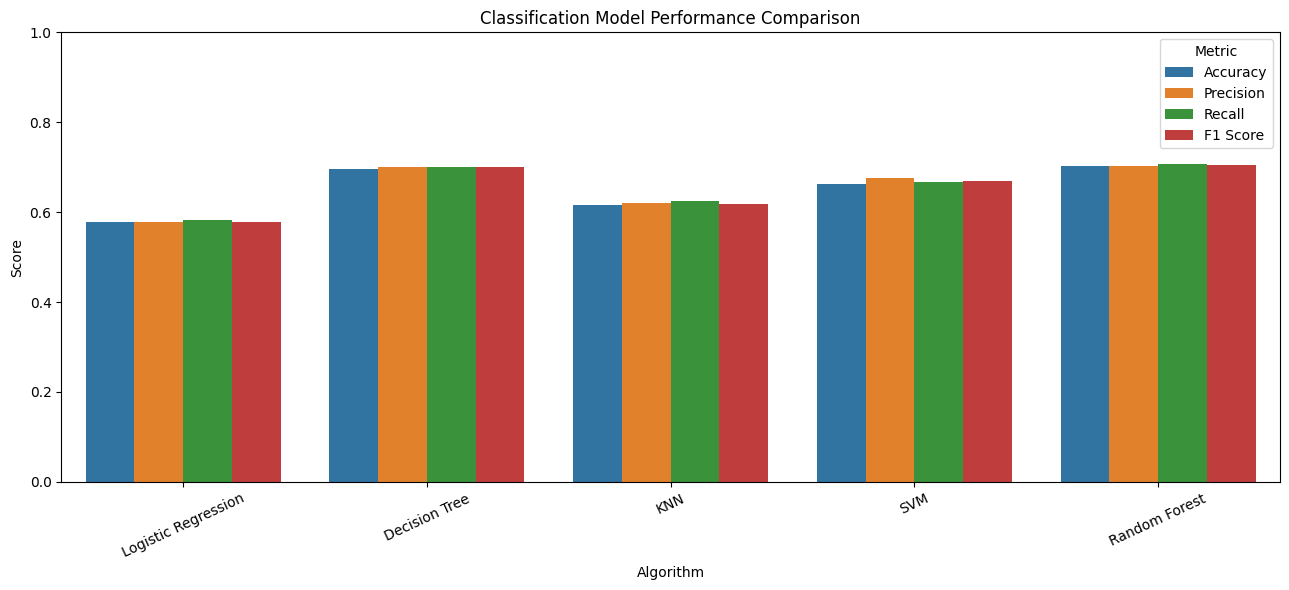

BEST CLASSIFICATION MODEL: Random Forest

CLASSIFICATION REPORT
              precision    recall  f1-score   support

        High       0.68      0.72      0.70       218
         Low       0.80      0.81      0.81       200
      Medium       0.63      0.58      0.60       229

    accuracy                           0.70       647
   macro avg       0.70      0.71      0.70       647
weighted avg       0.70      0.70      0.70       647



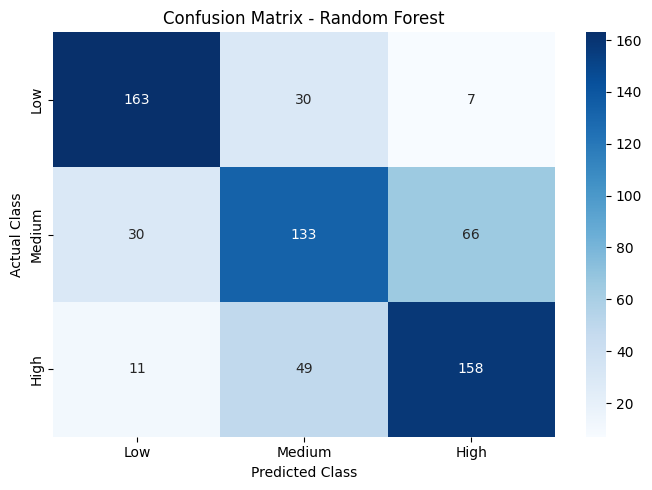

In [20]:

plot_df = classification_df.melt(
    id_vars="Algorithm",
    value_vars=[
        "Accuracy", "Precision", "Recall", "F1 Score"
    ],
    var_name="Metric",
    value_name="Score"
)

plt.figure(figsize=(13, 6))
sns.barplot(
    data=plot_df, x="Algorithm",
    y="Score", hue="Metric"
)
plt.title("Classification Model Performance Comparison")
plt.ylim(0, 1)
plt.xticks(rotation=25)
plt.tight_layout()
plt.savefig("05_classification_comparison.png", dpi=200)
plt.show()

best_row = classification_df.loc[
    classification_df["F1 Score"].idxmax()
]

best_model_name = best_row["Algorithm"]
best_pred = predictions_dict[best_model_name]

print("BEST CLASSIFICATION MODEL:", best_model_name)

print("\nCLASSIFICATION REPORT")
print(classification_report(
    y_test, best_pred, zero_division=0
))

labels = ["Low", "Medium", "High"]

cm = confusion_matrix(
    y_test, best_pred, labels=labels
)

plt.figure(figsize=(7, 5))
sns.heatmap(
    cm, annot=True, fmt="d",
    xticklabels=labels,
    yticklabels=labels,
    cmap="Blues"
)

plt.title("Confusion Matrix - " + best_model_name)
plt.xlabel("Predicted Class")
plt.ylabel("Actual Class")
plt.tight_layout()
plt.savefig("06_confusion_matrix.png", dpi=200)
plt.show()



## Phase 4: Cross-Validation and Model Optimization

Five-fold stratified cross-validation is used to estimate model performance on different training subsets.

GridSearchCV is applied to Random Forest to compare different hyperparameter combinations.

The best hyperparameters are selected using macro F1 Score on the training data. The independent test set is then used for final evaluation.

This helps reduce the risk of selecting a model based only on a single training result.


In [21]:

from sklearn.model_selection import GridSearchCV, StratifiedKFold

cv = StratifiedKFold(
    n_splits=5, shuffle=True, random_state=42
)

rf_pipeline = make_pipeline(
    SimpleImputer(strategy="median"),
    RandomForestClassifier(
        random_state=42, n_jobs=-1
    )
)

param_grid = {
    "randomforestclassifier__n_estimators": [50, 100],
    "randomforestclassifier__max_depth": [5, 10, None],
    "randomforestclassifier__min_samples_leaf": [1, 3]
}

grid = GridSearchCV(
    rf_pipeline,
    param_grid=param_grid,
    cv=cv,
    scoring="f1_macro",
    n_jobs=-1
)

grid.fit(X_train, y_train)

optimized_pred = grid.predict(X_test)

optimized_accuracy = accuracy_score(
    y_test, optimized_pred
)
optimized_f1 = f1_score(
    y_test, optimized_pred,
    average="macro"
)

print("BEST HYPERPARAMETERS")
print(grid.best_params_)

print("\nBEST CROSS-VALIDATION F1")
print(round(grid.best_score_, 4))

print("\nOPTIMIZED MODEL TEST ACCURACY")
print(round(optimized_accuracy, 4))

print("\nOPTIMIZED MODEL TEST F1")
print(round(optimized_f1, 4))

print("\nDETAILED CLASSIFICATION REPORT")
print(classification_report(
    y_test, optimized_pred, zero_division=0
))


BEST HYPERPARAMETERS
{'randomforestclassifier__max_depth': 10, 'randomforestclassifier__min_samples_leaf': 1, 'randomforestclassifier__n_estimators': 100}

BEST CROSS-VALIDATION F1
0.7069

OPTIMIZED MODEL TEST ACCURACY
0.7048

OPTIMIZED MODEL TEST F1
0.7086

DETAILED CLASSIFICATION REPORT
              precision    recall  f1-score   support

        High       0.71      0.70      0.70       218
         Low       0.80      0.81      0.81       200
      Medium       0.62      0.61      0.62       229

    accuracy                           0.70       647
   macro avg       0.71      0.71      0.71       647
weighted avg       0.70      0.70      0.70       647



In [22]:

print("=" * 60)
print("AIML ACTIVITY - COMPARATIVE RESULT ANALYSIS")
print("=" * 60)

for dataset_name in ["Steel", "MatNavi"]:
    subset = regression_df[
        regression_df["Dataset"] == dataset_name
    ]
    best = subset.loc[subset["R2"].idxmax()]

    print(f"\n{dataset_name} Regression")
    print("Best Model:", best["Algorithm"])
    print("MAE:", best["MAE"])
    print("RMSE:", best["RMSE"])
    print("R2:", best["R2"])

best_class = classification_df.loc[
    classification_df["F1 Score"].idxmax()
]

print("\nBest Classification Model:")
print("Algorithm:", best_class["Algorithm"])
print("Accuracy:", round(best_class["Accuracy"], 4))
print("F1 Score:", round(best_class["F1 Score"], 4))

print("\nOptimized Random Forest:")
print("Cross-validation F1:", round(grid.best_score_, 4))
print("Test Accuracy:", round(optimized_accuracy, 4))
print("Test F1:", round(optimized_f1, 4))

print("\nCONCLUSION")
print("""
This activity implemented regression and classification
algorithms to analyze steel mechanical properties.

The models were compared using suitable evaluation
metrics to identify differences in prediction performance.

Regression was performed separately for the Steel and
MatNavi datasets. Classification was performed using
strength categories derived from the Steel training data.

Cross-validation and hyperparameter tuning were applied
to a Random Forest classification model.

The results demonstrate the importance of feature
selection, preprocessing, algorithm selection and
model evaluation.

These models are educational prediction tools and
should not replace laboratory measurements or
engineering safety verification.
""")


AIML ACTIVITY - COMPARATIVE RESULT ANALYSIS

Steel Regression
Best Model: Random Forest
MAE: 123.251
RMSE: 176.274
R2: 0.6682

MatNavi Regression
Best Model: Random Forest
MAE: 19.789
RMSE: 30.83
R2: 0.9325

Best Classification Model:
Algorithm: Random Forest
Accuracy: 0.7017
F1 Score: 0.7046

Optimized Random Forest:
Cross-validation F1: 0.7069
Test Accuracy: 0.7048
Test F1: 0.7086

CONCLUSION

This activity implemented regression and classification
algorithms to analyze steel mechanical properties.

The models were compared using suitable evaluation
metrics to identify differences in prediction performance.

Regression was performed separately for the Steel and
MatNavi datasets. Classification was performed using
strength categories derived from the Steel training data.

Cross-validation and hyperparameter tuning were applied
to a Random Forest classification model.

The results demonstrate the importance of feature
selection, preprocessing, algorithm selection and
model evaluation.



## Phase 5: Discussion, Ethics and Reflection

### Discussion
Regression models were compared using MAE, MSE, RMSE and R² Score. Classification models were compared using accuracy, precision, recall and F1 Score.

Different algorithms produced different results because they learn relationships in different ways. Linear models estimate linear relationships, while Decision Trees, SVM and Random Forest can capture nonlinear patterns.

Steel and MatNavi were evaluated independently because their datasets contain different material records and experimental conditions.

### Limitations
1. Prediction quality depends on the size and quality of the training dataset.
2. Some material properties depend on heat treatment and manufacturing conditions that may not be fully represented.
3. Random splitting may place closely related material records in both training and testing sets.
4. The classification categories are dataset-relative, not established material safety grades.
5. Further evaluation using unseen materials is needed before real-world use.

### Ethical and Safety Considerations
Incorrect predictions about mechanical strength may create engineering safety risks. Therefore, machine learning predictions must be independently verified through material testing before use in safety-critical applications.

### Personal Reflection
Through this activity, I learned how to prepare data, select input features, train different regression and classification models, evaluate prediction errors and compare algorithms.

I also learned that high accuracy alone does not guarantee a reliable model. Cross-validation, suitable performance metrics, and careful evaluation are necessary.

### Future Scope
- Include additional manufacturing and heat-treatment information.
- Evaluate grouping-based train/test splits.
- Test more advanced ensemble algorithms.
- Validate models using independent material datasets.
- Develop an interactive material prediction application.


## Result

In this activity, different Machine Learning algorithms were successfully implemented and evaluated using the Steel and MatNavi datasets. Six regression algorithms, including Linear Regression, Ridge Regression, Decision Tree, KNN, SVR, and Random Forest, were compared using MAE, MSE, RMSE, and R² Score.

The **Random Forest Regressor** achieved the best performance, with an R² Score of **0.6682 (66.82%)** on the Steel dataset and **0.9325 (93.25%)** on the MatNavi dataset.

For steel strength classification, five algorithms were compared using Accuracy, Precision, Recall, and F1 Score. The **Random Forest Classifier** achieved the highest accuracy of **70.17%**, which improved to **70.48%** after hyperparameter optimization.

The results demonstrate that Random Forest performed better than the other tested algorithms for predicting and classifying steel mechanical properties in these experiments.

## Conclusion

This activity successfully demonstrated the implementation and comparative performance analysis of various Machine Learning algorithms for steel mechanical property prediction and classification. Data preprocessing, visualization, model training, testing, cross-validation, and performance evaluation were performed.

Random Forest emerged as the best-performing algorithm due to its ability to capture complex and nonlinear relationships in the datasets. The activity provided practical knowledge of Regression, Classification, model optimization, and evaluation techniques.

In conclusion, Machine Learning can support steel material property prediction and analysis, potentially reducing the need for repeated preliminary testing. However, predictions should be validated through experimental testing before use in real-world engineering applications.